In [1]:
import re
from pathlib import Path
import numpy as np
from collections import defaultdict
import matplotlib.pyplot as plt
from matplotlib import cm
import pandas as pd
from glob import glob
import sys, os
import seaborn as sns

from matplotlib.lines import Line2D
from metrics import full_map_cover_time, roi_first_visit_per_cfg, roi_first_visit_static, convergence_errors_from_run, empirical_full, empirical_soft_forget, empirical_from_traj


In [2]:
def parse_run_name(folder_name):
    info = {}
    info["is_mac_dt"] = "mac_dt" in folder_name
    info["is_ergodic"] = "ergodic" in folder_name
    info["gp_policy"] = "gpucb" if "gpucb" in folder_name else "gpmean"

    m = re.search(r"starts(\d+)", folder_name)
    info["starts"] = m.group(1) if m else None

    m = re.search(r"T(\d+)", folder_name)
    info["T"] = int(m.group(1)) if m else None

    return info

In [3]:
def load_run_npz(run_dir):
    npz_path = next(Path(run_dir).glob("run_*.npz"))
    return np.load(npz_path, allow_pickle=True)

In [4]:
def get_method_label(npz):
    keys = set(npz.files)

    # --- planner is the PRIMARY identifier ---
    if "planner" in keys:
        planner = npz["planner"].item()

    elif "stem" in keys:
        # infer from stem (this matches your run() logic exactly)
        stem = npz["stem"].item()
        if "mac_dt" in stem:
            planner = "mac_dt"
        elif "ergodic" in stem:
            planner = "ergodic"
        else:
            raise ValueError(f"Cannot infer planner from stem: {stem}")

    else:
        raise ValueError("Cannot determine planner from npz")

    # --- GP mode (safe default) ---
    gp_mode = npz["gp_mode"].item() if "gp_mode" in keys else None

    # --- method ONLY for ergodic ---
    method = npz["method"].item() if ("method" in keys and planner == "ergodic") else None

    # --- final clean label ---
    if planner == "ergodic":
        label = "ergodic" if method is None else f"ergodic-{method}"
    elif planner == "mac_dt":
        label = "mac-dt"
    else:
        label = planner

    # append GP mode if desired
    if gp_mode is not None:
        label = f"{label}-{gp_mode}"

    return label



In [5]:
def detect_cfg_starts(true_phi_map_time, atol=1e-12):
    T = true_phi_map_time.shape[0]
    starts = [0]
    for t in range(1, T):
        if not np.allclose(true_phi_map_time[t], true_phi_map_time[t-1], atol=atol):
            starts.append(t)
    return np.array(starts, dtype=int)

def cfg_intervals_from_true_phi(true_phi_map_time, T_traj):
    cfg_starts = detect_cfg_starts(true_phi_map_time)
    T_end = min(T_traj, true_phi_map_time.shape[0])

    intervals = []
    for i, t0 in enumerate(cfg_starts):
        t1 = cfg_starts[i+1] if i+1 < len(cfg_starts) else T_end
        intervals.append((i, int(t0), int(min(t1, T_end))))
    return cfg_starts, intervals

In [6]:


def extract_map_id_from_name(run_name):
    """
    Extracts map id like 'v0', 'v1', etc. from run folder name.
    """
    m = re.search(r"_v(\d+)_", run_name)
    if m:
        return f"v{m.group(1)}"
    else:
        return None
    
def extract_start_from_name(run_name):
    """
    Extract start index from run folder name.
    Matches both 'start00' and 'starts00'.
    """
    m = re.search(r"starts?(\d+)", run_name)

    if m:
        return m.group(1)
    else:
        return None
    


sys.path.append(os.path.abspath(".."))
sys.path.append(os.getcwd())
from env.grid import make_env_from_json
def recover_state_index_map(data):
    """
    Recover state_index_map for legacy runs that did not save it.
    """
    # Case 1: already present (new runs)
    if "state_index_map" in data:
        sim = data["state_index_map"]
        # np.load returns object arrays sometimes
        return sim.item() if hasattr(sim, "item") else sim

    # Case 2: reconstruct from env_source

    env_source = data.get("env_source", None)
    
    
    if env_source is None:
        raise RuntimeError("Cannot recover state_index_map: env_source missing")
    
    if isinstance(env_source, np.ndarray):
        env_source = env_source.item()
        print("env_source:", env_source)

    # Rebuild environment exactly as in the run
    if data["env_dyn"] == "dynamic":
        # env_source is a folder → first config defines indexing
        import glob
        json_files = sorted(glob.glob(os.path.join(env_source, "*.json")))
        if not json_files:
            raise RuntimeError(f"No JSON files found in {env_source}")
        env = make_env_from_json(json_files[0])
    else:
        env = make_env_from_json(env_source)

    # Force indexing (exact same logic as simulation)
    env._indexing()
    env._precompute_graph()

    return env._state_index_map

In [7]:


def build_roi_cellsets(roi_rc, roi_name):
    """
    Returns dict: roi_name -> set of (r,c)
    """
    roi_sets = {}
    for (r, c), name in zip(roi_rc, roi_name):
        name = str(name)
        roi_sets.setdefault(name, set()).add((int(r), int(c)))
    return roi_sets




### Analysis of different Algorithms

In [47]:
BATCH_DIR = Path("/home/gaby/Documents/UCB/AAM/GIT/sastryrepo/MarkovErgodic/MAES/results/PlannerComparison5x5_0214")
for run_dir in list(BATCH_DIR.iterdir()):
    npz = load_run_npz(run_dir)
    print(run_dir.name, "→", get_method_label(npz))
print(len(list(BATCH_DIR.iterdir())))

T300_ergodic_GPupdate50_remc_Pupdate50_v0_gpucb_static_3_start31x3_commModelocal_comm_radius5.0_concenIter5 → ergodic-remc-ucb
T300_ergodic_GPupdate50_remc_Pupdate50_v0_gpucb_static_3_start40x3_commModelocal_comm_radius5.0_concenIter5 → ergodic-remc-ucb
T300_mac_dt_GPupdate50_v2_gpucb_static_3_start00x3_commModelocal_comm_radius5.0_concenIter5 → mac-dt-ucb
T300_mac_dt_GPupdate50_v0_gpucb_static_3_start44x3_commModelocal_comm_radius5.0_concenIter5 → mac-dt-ucb
T300_mac_dt_GPupdate50_v0_gpucb_static_3_start40x3_commModelocal_comm_radius5.0_concenIter5 → mac-dt-ucb
T300_ergodic_GPupdate50_remc_Pupdate50_v0_gpucb_static_3_start23x3_commModelocal_comm_radius5.0_concenIter5 → ergodic-remc-ucb
T300_mac_dt_GPupdate50_v2_gpucb_static_3_start44x3_commModelocal_comm_radius5.0_concenIter5 → mac-dt-ucb
T300_ergodic_GPupdate50_remc_Pupdate50_v2_gpucb_static_3_start02x3_commModelocal_comm_radius5.0_concenIter5 → ergodic-remc-ucb
T300_mac_dt_GPupdate50_v2_gpucb_static_3_start02x3_commModelocal_comm_ra

In [51]:
cover_rows = []

for run_dir in BATCH_DIR.iterdir():
    if not run_dir.is_dir():
        continue

    npz = load_run_npz(run_dir)

    label = get_method_label(npz)
    map_id = extract_map_id_from_name(run_dir.name)
    agent_starts = extract_start_from_name(run_dir.name)
    n_agents = int(npz["n_agents"])
    nstates = int(npz["nstates"])

    traj_states = npz["traj_states"]  
    true_phi_map_time = npz["true_phi_map_time"]
    state_index_map = recover_state_index_map(npz)

    full_cellset = set((int(r), int(c)) for (r, c) in state_index_map.keys())


    cfg_starts = detect_cfg_starts(true_phi_map_time)
    cover_time = full_map_cover_time(
        traj_states=traj_states,
        nstates=nstates,
    )

    cover_rows.append({
        "run": run_dir.name,
        "map_id": map_id,
        "n_agents": n_agents,
        "algorithm": label,
        "cover_time": cover_time,
        "agent_starts": agent_starts,
    })

map_df = (
    pd.DataFrame(cover_rows)
    .sort_values(["map_id", "algorithm", "n_agents", "agent_starts"])
    .reset_index(drop=True)
)

display(map_df)




,run,map_id,n_agents,algorithm,cover_time,agent_starts
0,T300_ergodic_GPupdate50_remc_Pupdate50_v0_gpuc...,v0,3,ergodic-remc-ucb,27.0,23
1,T300_ergodic_GPupdate50_remc_Pupdate50_v0_gpuc...,v0,3,ergodic-remc-ucb,57.0,31
2,T300_ergodic_GPupdate50_remc_Pupdate50_v0_gpuc...,v0,3,ergodic-remc-ucb,57.0,40
3,T300_ergodic_GPupdate50_remc_Pupdate50_v0_gpuc...,v0,3,ergodic-remc-ucb,36.0,44
4,T300_mac_dt_GPupdate50_v0_gpucb_static_3_start...,v0,3,mac-dt-ucb,NaN,23
5,T300_mac_dt_GPupdate50_v0_gpucb_static_3_start...,v0,3,mac-dt-ucb,NaN,31
6,T300_mac_dt_GPupdate50_v0_gpucb_static_3_start...,v0,3,mac-dt-ucb,NaN,40
7,T300_mac_dt_GPupdate50_v0_gpucb_static_3_start...,v0,3,mac-dt-ucb,NaN,44
8,T300_ergodic_GPupdate50_remc_Pupdate50_v2_gpuc...,v2,3,ergodic-remc-ucb,53.0,00
9,T300_ergodic_GPupdate50_remc_Pupdate50_v2_gpuc...,v2,3,ergodic-remc-ucb,53.0,02


In [56]:
cover_df = map_df
cover_summary = (
    cover_df
    .groupby("algorithm", as_index=False)
    .agg(
        mean_cover_time=("cover_time", "mean"),
        std_cover_time=("cover_time", "std"),
        success_rate=("cover_time", lambda x: x.notna().mean()),
        n_runs=("cover_time", "count"),
    )
)

cover_summary

,algorithm,mean_cover_time,std_cover_time,success_rate,n_runs
0,ergodic-remc-ucb,45.571429,12.245505,1.000000,7
1,mac-dt-ucb,105.000000,NaN,0.142857,1


In [ ]:
roi_rows = []

for run_dir in BATCH_DIR.iterdir():
    if not run_dir.is_dir():
        continue

    npz = load_run_npz(run_dir)

    label = get_method_label(npz)
    map_id = extract_map_id_from_name(run_dir.name)
    agent_starts = extract_start_from_name(run_dir.name)
    n_agents = int(npz["n_agents"])
    env_dyn = str(npz["env_dyn"])

    traj_rc_all = np.asarray(npz["traj_rc_agents_all"])
    true_phi_map_time = npz["true_phi_map_time"]

    roi_sets = build_roi_cellsets(npz["roi_rc"], npz["roi_name"])



    for r in rows:
        roi_rows.append({
            **r,
            "run": run_dir.name,
            "map_id": map_id,
            "algorithm": label,
            "n_agents": n_agents,
            "agent_starts": agent_starts,
        })

roi_df = pd.DataFrame(roi_rows)
roi_df = roi_df.sort_values(
    ["map_id", "algorithm", "n_agents", "cfg","roi"]
).reset_index(drop=True)

display(roi_df)


In [ ]:
roi_df = roi_df

roi_summary = (
    roi_df
    .groupby(["algorithm", "roi"], as_index=False)
    .agg(
        mean_visit_time=("visit_time", "mean"),
        std_visit_time=("visit_time", "std"),
        n_runs=("visit_time", "count"),
    )
)

roi_summary

In [ ]:
def compute_three_errors_from_series(
    emp_series,
    phi_hat_series,      # \hat{\phi}(t)  -> use npz["phi_norm_series"]
    true_phi_series,     # \phi^*(t)      -> use npz["true_phi_map_time"]
    stride=1,
):
    def _normalize(v):
        v = np.clip(np.asarray(v, dtype=float), 0.0, None)
        s = v.sum()
        return v / s if s > 0 else v

    T = min(len(emp_series), len(phi_hat_series), len(true_phi_series))
    xs = np.arange(0, T, stride)

    err_emp_true, err_emp_belief, err_bel_true = [], [], []

    for t in xs:
        rhat = _normalize(emp_series[t])
        phat = _normalize(phi_hat_series[t])
        ptru = _normalize(true_phi_series[t])

        err_emp_true.append(np.linalg.norm(rhat - ptru, ord=1))
        err_emp_belief.append(np.linalg.norm(rhat - phat, ord=1))
        err_bel_true.append(np.linalg.norm(phat - ptru, ord=1))

    return (
        xs,
        np.array(err_emp_true),
        np.array(err_emp_belief),
        np.array(err_bel_true),
    )



In [ ]:
curves_emp_true   = defaultdict(list)
curves_emp_belief = defaultdict(list)
curves_bel_true   = defaultdict(list)

for run_dir in BATCH_DIR.iterdir():
    if not run_dir.is_dir():
        continue

    npz = load_run_npz(run_dir)
    label = get_method_label(npz)

    x, e_et, e_eb, e_bt = compute_three_errors_from_series(
        emp_series=npz["emp_series"],
        phi_hat_series=npz["phi_norm_series"],
        true_phi_series=npz["true_phi_map_time"],
        stride=1,
    )

    curves_emp_true[label].append(e_et)
    curves_emp_belief[label].append(e_eb)
    curves_bel_true[label].append(e_bt)

In [ ]:
from matplotlib.lines import Line2D
# these are IEEE plot settings
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["DejaVu Sans"],
    "mathtext.fontset": "cm",
    "font.size": 12,
    "axes.labelsize": 13,
    "axes.titlesize": 14,
    "legend.fontsize": 11,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "lines.linewidth": 2.4,
})


fig, ax = plt.subplots(figsize=(8.0, 4.8))  # width > height, clean

# Colorblind-safe palette (Okabe–Ito inspired)
# color_map = {
#     "ergodic-remc-ucb": "#0072B2",  # blue
#     "mac-dt-ucb":       "#D55E00",  # vermillion
# }
# color_map = {
#     "ergodic-remc-ucb": "#6B8EC1",
#     "mac-dt-ucb":         "#E3A26E",
# }
color_map = {
    "ergodic-remc-ucb": "#4C72B0",  # muted blue
    "mac-dt-ucb":         "#DD8452",  # muted orange
}

# Line styles encode metric
metric_styles = {
    "emp_true": dict(linestyle="-",  alpha=0.12),
    "bel_true": dict(linestyle="--", alpha=0.12),
}


method_name_map = {
    "ergodic-remc-ucb": "MA-Ergodic",
    "mac-dt-ucb": "MAC-DT",
}
# ----------------------------
# Plot curves
# ----------------------------
for label in curves_emp_true.keys():

    c = color_map[label]

    # --- Empirical − True (solid) ---
    Ys = curves_emp_true[label]
    min_len = min(len(y) for y in Ys)
    Y = np.stack([y[:min_len] for y in Ys])

    mean = Y.mean(axis=0)
    std  = Y.std(axis=0)
    x = np.arange(min_len)

    ax.plot(
        x, mean,
        color=c,
        linestyle="-",
        label=method_name_map[label]
    )
    ax.fill_between(
        x, mean - std, mean + std,
        color=c,
        alpha=metric_styles["emp_true"]["alpha"],
        linewidth=0
    )

    # --- Belief − True (dashed) ---
    Ys = curves_bel_true[label]
    min_len = min(len(y) for y in Ys)
    Y = np.stack([y[:min_len] for y in Ys])

    mean = Y.mean(axis=0)
    std  = Y.std(axis=0)
    x = np.arange(min_len)

    ax.plot(
        x, mean,
        color=c,
        linestyle="--"
    )
    ax.fill_between(
        x, mean - std, mean + std,
        color=c,
        alpha=metric_styles["bel_true"]["alpha"],
        linewidth=0
    )

# ----------------------------
# Axes, grid, labels
# ----------------------------
ax.set_xlabel("Time step")
ax.set_ylabel(r"$\ell_1$ error")

ax.grid(
    True,
    which="major",
    axis="y",
    alpha=0.25,
    linewidth=0.8
)


ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)


method_handles = [
    Line2D([0], [0], color=color_map["ergodic-remc-ucb"], lw=2.0, label="MA-Ergodic"),
    Line2D([0], [0], color=color_map["mac-dt-ucb"], lw=2.0, label="MAC-DT"),
]

metric_handles = [
    Line2D([0], [0], color="black", lw=2.0, linestyle="-",
           label=r"$\|\hat{\rho} - \bar{\rho}\|_1$ (empirical vs belief)"),
    Line2D([0], [0], color="black", lw=1.5, linestyle="--",
           label=r"$\|\hat{\rho} - \bar{\rho^\star}\|_1$ (belief vs true)"),
]

# legend_lines = [
#     plt.Line2D([0], [0], color="black", linestyle="-",  linewidth=2.4),
#     plt.Line2D([0], [0], color="black", linestyle="--", linewidth=2.4),
# ]

# legend_labels = [
#     r"$\|\hat r - \phi^{\star}\|_1$ (empirical vs true)",
#     r"$\|\hat\phi - \phi^{\star}\|_1$ (belief vs true)",
# ]

leg1 = ax.legend(handles=method_handles, title="Method",
                 loc="upper right", frameon=False)
leg2 = ax.legend(handles=metric_handles, title="Metric",
                 loc="upper center", frameon=False)


ax.add_artist(leg1)

plt.tight_layout()
plt.show()

In [ ]:
# ## To cehck the beleifs of each agents - not fully 
npz = load_run_npz("/home/gaby/Documents/UCB/AAM/GIT/sastryrepo/MarkovErgodic/MAES/results/T300_ergodic_GPupdate25_remc_Pupdate25_v0_gpucb_static_3_starts313131_commModelocal_comm_radius10.0_concenIter5")
phi = npz["phi_agents_time"]   # (T, A, S)
print(phi.shape)
align = np.linalg.norm(phi[:,0,:] - phi[:,1,:], axis=1)
var_phi = np.var(phi, axis=1)  # (T, S)
print(var_phi.shape)
obs = npz["obs_count_agents"]
print(obs.shape)
agent_maps = obs.sum(axis=0)   # (A, S)
print(agent_maps)

### Analysis of communication radius effect in Ergodic 

In [8]:
BATCH_DIR = Path("/home/gaby/Documents/UCB/AAM/GIT/sastryrepo/MarkovErgodic/MAES/results/Analysis_Comms_Init6_021126")
for run_dir in list(BATCH_DIR.iterdir()):
    npz = load_run_npz(run_dir)
    print(run_dir.name, "→", get_method_label(npz))
print(len(list(BATCH_DIR.iterdir())))

T1000_ergodic_GPupdate50_remc_Pupdate50_v1_gpucb_static_3_start09x3_commModelocal_comm_radius1.0_concenIter5 → ergodic-remc-ucb
T1000_ergodic_GPupdate50_remc_Pupdate50_v3_gpucb_static_6_start54x6_commModelocal_comm_radius30.0_concenIter5 → ergodic-remc-ucb
T1000_ergodic_GPupdate50_remc_Pupdate50_v3_gpucb_static_10_start91x10_commModelocal_comm_radius30.0_concenIter5 → ergodic-remc-ucb
T1000_ergodic_GPupdate50_remc_Pupdate50_v3_gpucb_static_6_start07x6_commModelocal_comm_radius5.0_concenIter5 → ergodic-remc-ucb
T1000_ergodic_GPupdate50_remc_Pupdate50_v3_gpucb_static_6_start90x6_commModelocal_comm_radius30.0_concenIter5 → ergodic-remc-ucb
T1000_ergodic_GPupdate50_remc_Pupdate50_v3_gpucb_static_10_start91x10_commModelocal_comm_radius5.0_concenIter5 → ergodic-remc-ucb
T1000_ergodic_GPupdate50_remc_Pupdate50_v3_gpucb_static_10_start91x10_commModelocal_comm_radius1.0_concenIter5 → ergodic-remc-ucb
T1000_ergodic_GPupdate50_remc_Pupdate50_v1_gpucb_static_3_start49x3_commModelocal_comm_radius1.

In [9]:
roi_rows = []

for run_dir in BATCH_DIR.iterdir():
    if not run_dir.is_dir():
        continue

    npz = load_run_npz(run_dir)

    traj_rc_all = np.asarray(npz["traj_rc_agents_all"])
    true_phi_map_time = npz["true_phi_map_time"]
    env_dyn = str(npz["env_dyn"])

    map_id = extract_map_id_from_name(run_dir.name)
    n_agents = int(npz["n_agents"])
    comm_radius = npz["comm_radius"].item()
    agent_starts = extract_start_from_name(run_dir.name)

    roi_sets = build_roi_cellsets(
        npz.get("roi_rc", []),
        npz.get("roi_name", [])
    )


    # normally these are run static but if dynamic needed call the other function
    for roi_name, cellset in roi_sets.items():
        t = roi_first_visit_static(traj_rc_all, cellset)

        roi_rows.append({
            "run": run_dir.name,
            "map_id": map_id,
            "roi_name": roi_name,
            "cfg": 0,
            "roi_cover_time": t,
            "comm_radius": comm_radius,
            "n_agents": n_agents,
            "agent_starts": agent_starts,
        })




roi_df = pd.DataFrame(roi_rows)

from IPython.display import display
# display(roi_df)
with pd.option_context("display.max_rows", None):
    display(roi_df)



,run,map_id,roi_name,cfg,roi_cover_time,comm_radius,n_agents,agent_starts
0,T1000_ergodic_GPupdate50_remc_Pupdate50_v1_gpu...,v1,roi1,0,35,1.0,3,09
1,T1000_ergodic_GPupdate50_remc_Pupdate50_v1_gpu...,v1,roi2,0,4,1.0,3,09
2,T1000_ergodic_GPupdate50_remc_Pupdate50_v1_gpu...,v1,roi3,0,41,1.0,3,09
3,T1000_ergodic_GPupdate50_remc_Pupdate50_v3_gpu...,v3,roi1,0,79,30.0,6,54
4,T1000_ergodic_GPupdate50_remc_Pupdate50_v3_gpu...,v3,roi2,0,12,30.0,6,54
5,T1000_ergodic_GPupdate50_remc_Pupdate50_v3_gpu...,v3,roi3,0,1,30.0,6,54
6,T1000_ergodic_GPupdate50_remc_Pupdate50_v3_gpu...,v3,roi4,0,4,30.0,6,54
7,T1000_ergodic_GPupdate50_remc_Pupdate50_v3_gpu...,v3,roi5,0,8,30.0,6,54
8,T1000_ergodic_GPupdate50_remc_Pupdate50_v3_gpu...,v3,roi1,0,151,30.0,10,91
9,T1000_ergodic_GPupdate50_remc_Pupdate50_v3_gpu...,v3,roi2,0,82,30.0,10,91


In [21]:

# roi_summary = (
#     roi_df
#     .groupby(["comm_radius", "roi_name"], as_index=False) #averaging over
#     .agg(
#         mean_cover_time=("roi_cover_time", "mean"),
#         std_cover_time=("roi_cover_time", "std"),
#         n_runs=("roi_cover_time", "count"),
#     ) 
# )

roi_summary = (
    roi_df
    .groupby(["n_agents", "comm_radius", "roi_name"], as_index=False) #averaging over
    .agg(
        mean_cover_time=("roi_cover_time", "mean"),
        std_cover_time=("roi_cover_time", "std"),
        n_runs=("roi_cover_time", "count"),
    ) 
)


# roi_summary_median = (
#     roi_df
#     .groupby(["n_agents", "comm_radius", "roi_name"], as_index=False)
#     .agg(
#         median_cover_time=("roi_cover_time", "median"),
#         iqr_cover_time=("roi_cover_time", lambda x: x.quantile(0.75) - x.quantile(0.25)),
#     )
# )
# roi_df["roi_cover_time_norm"] = (
#     roi_df["roi_cover_time"]
#     / roi_df.groupby(["map_id", "roi_name"])["roi_cover_time"].transform("median")
# )

roi_summary_norm = (
    roi_df
    .groupby(["n_agents", "comm_radius"], as_index=False)
    .agg(
        mean_norm_time=("roi_cover_time_norm", "mean"),
        std_norm_time=("roi_cover_time_norm", "std"),
    )
)

display(roi_summary)

,n_agents,comm_radius,roi_name,mean_cover_time,std_cover_time,n_runs
0,3,1.0,roi1,72.000000,52.325902,2
1,3,1.0,roi2,8.000000,5.656854,2
2,3,1.0,roi3,43.000000,2.828427,2
3,3,5.0,roi1,69.500000,48.790368,2
4,3,5.0,roi2,8.000000,5.656854,2
5,3,5.0,roi3,43.000000,2.828427,2
6,3,30.0,roi1,70.500000,50.204581,2
7,3,30.0,roi2,8.000000,5.656854,2
8,3,30.0,roi3,43.000000,2.828427,2
9,6,1.0,roi1,54.666667,49.399730,3


In [11]:
display(roi_summary_norm)

,n_agents,comm_radius,mean_norm_time,std_norm_time
0,3,1.0,1.011990,0.463227
1,3,5.0,1.000000,0.446578
2,3,30.0,1.004796,0.453082
3,6,1.0,1.948287,2.633204
4,6,5.0,1.850159,2.590307
5,6,30.0,1.845584,2.593292
6,10,1.0,0.967616,0.597625
7,10,5.0,1.304550,1.056402
8,10,30.0,1.118954,0.840924


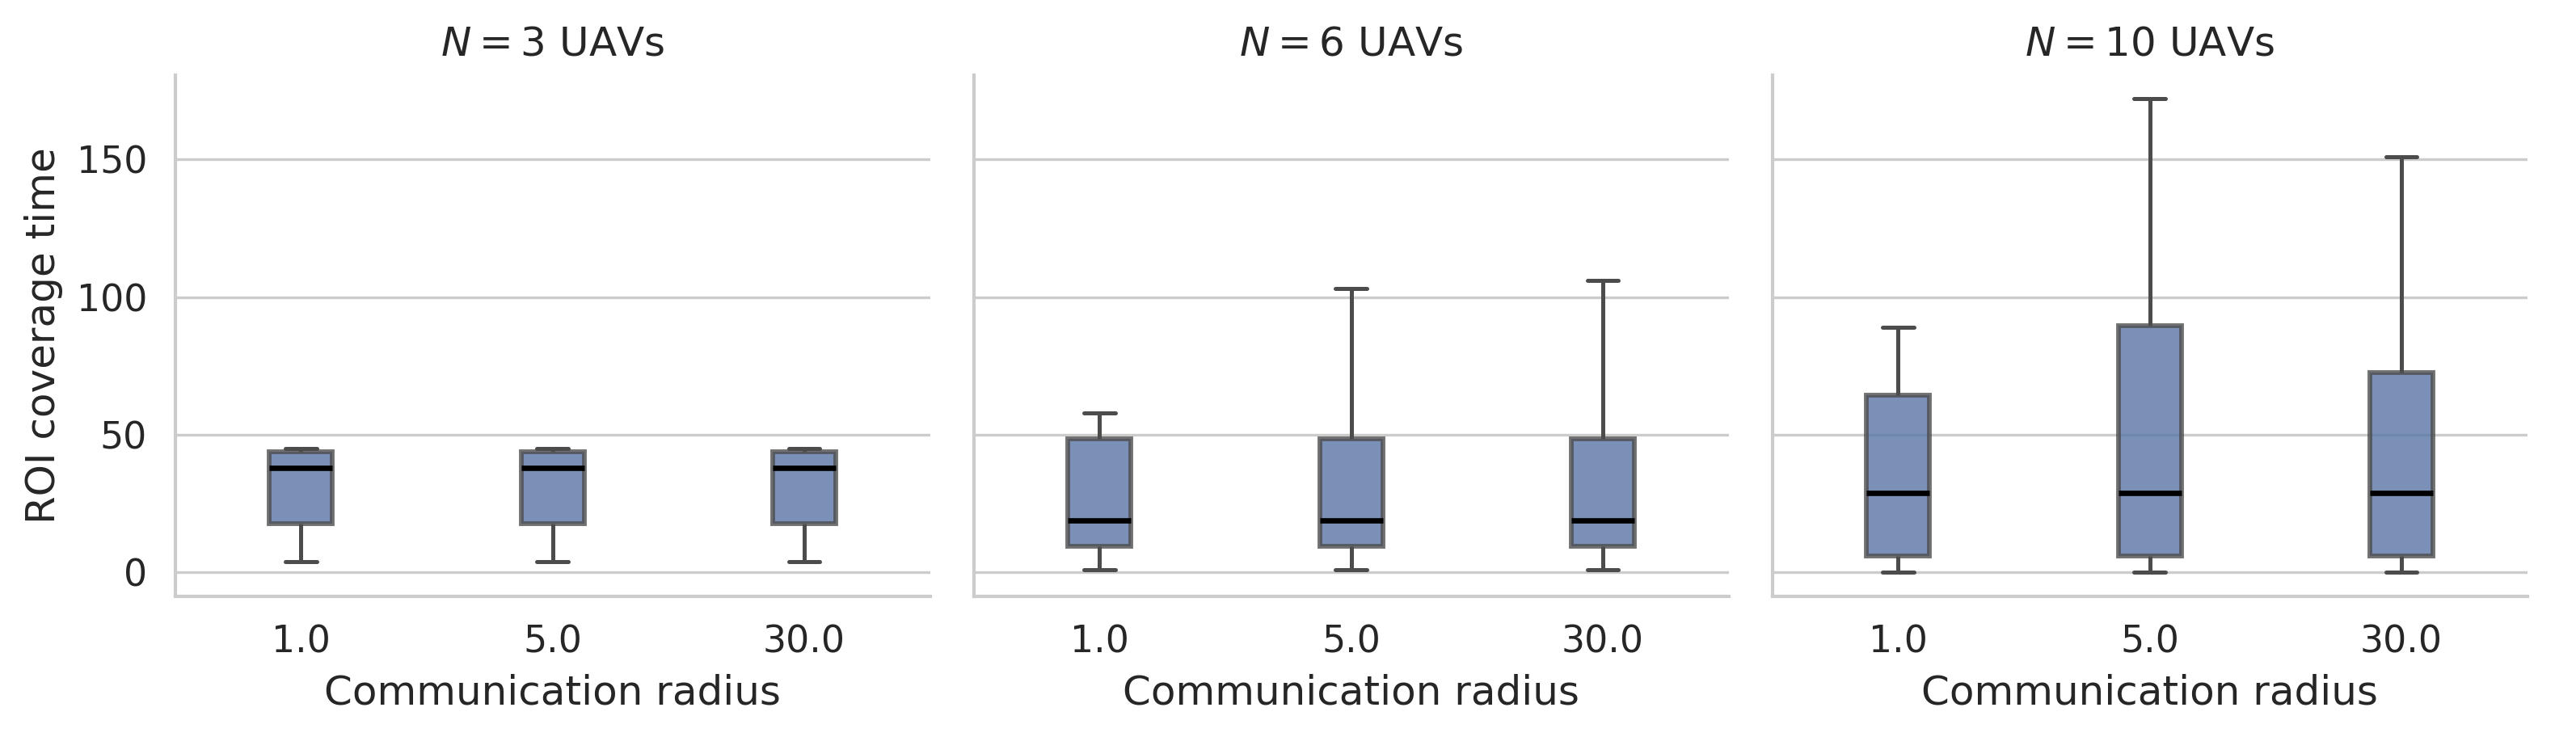

In [46]:

sns.set_theme(
    style="whitegrid",
    context="paper",
    font_scale=1.25   
)

g = sns.catplot(
    data=roi_df,
    x="comm_radius",
    y="roi_cover_time",
    col="n_agents",
    kind="box",
    showfliers=False,
    height=3.2,      
    aspect=1.1,       
    width=0.25,
    color="#4C72B0", 
    linewidth=1.4,
    boxprops=dict(alpha=0.8),
    whiskerprops=dict(linewidth=1.2),
    capprops=dict(linewidth=1.2),
    medianprops=dict(color="black", linewidth=1.6),
)

g.set_axis_labels(
    "Communication radius",
    "ROI coverage time"
)


g.set_titles(r"$N = {col_name}$ UAVs")

# Clean spines (IEEE style)
for ax in g.axes.flat:
    sns.despine(ax=ax)

plt.tight_layout()
plt.show()




In [24]:
cover_rows = []

for run_dir in BATCH_DIR.iterdir():
    if not run_dir.is_dir():
        continue

    npz = load_run_npz(run_dir)

    traj_states = npz["traj_states"]    
    n_agents = int(npz["n_agents"])
    nstates = int(npz["nstates"])
    assert str(npz["env_dyn"]) == "static", "Currently only supports static envs for full map coverage time"


    n_agents = int(npz["n_agents"])
    comm_radius = npz["comm_radius"].item()
    map_id = extract_map_id_from_name(run_dir.name)
    agent_starts = extract_start_from_name(run_dir.name)


    cover_time = full_map_cover_time(
        traj_states=traj_states,
        nstates=nstates,
    )

    cover_rows.append({
        "run": run_dir.name,
        "map_id": map_id,
        "n_agents": n_agents,
        "comm_radius": comm_radius,
        "cover_time": cover_time,
        "agent_starts": agent_starts,
    })



cover_df = pd.DataFrame(cover_rows)

from IPython.display import display
display(cover_df)


,run,map_id,n_agents,comm_radius,cover_time,agent_starts
0,T1000_ergodic_GPupdate50_remc_Pupdate50_v1_gpu...,v1,3,1.0,586,09
1,T1000_ergodic_GPupdate50_remc_Pupdate50_v3_gpu...,v3,6,30.0,125,54
2,T1000_ergodic_GPupdate50_remc_Pupdate50_v3_gpu...,v3,10,30.0,151,91
3,T1000_ergodic_GPupdate50_remc_Pupdate50_v3_gpu...,v3,6,5.0,159,07
4,T1000_ergodic_GPupdate50_remc_Pupdate50_v3_gpu...,v3,6,30.0,367,90
5,T1000_ergodic_GPupdate50_remc_Pupdate50_v3_gpu...,v3,10,5.0,134,91
6,T1000_ergodic_GPupdate50_remc_Pupdate50_v3_gpu...,v3,10,1.0,133,91
7,T1000_ergodic_GPupdate50_remc_Pupdate50_v1_gpu...,v1,3,1.0,310,49
8,T1000_ergodic_GPupdate50_remc_Pupdate50_v3_gpu...,v3,6,5.0,146,90
9,T1000_ergodic_GPupdate50_remc_Pupdate50_v1_gpu...,v1,3,30.0,318,49


In [25]:
cover_df["covered"] = cover_df["cover_time"].notna()

cover_summary = (
    cover_df
    .groupby(["n_agents", "comm_radius"], as_index=False)
    .agg(
        n_runs=("cover_time", "count"),
        success_rate=("covered", "mean"),
        mean_cover_time=("cover_time", "mean"),
        std_cover_time=("cover_time", "std"),
    )
)

cover_summary

,n_agents,comm_radius,n_runs,success_rate,mean_cover_time,std_cover_time
0,3,1.0,2,1.0,448.000000,195.161472
1,3,5.0,2,1.0,438.500000,194.454365
2,3,30.0,2,1.0,316.000000,2.828427
3,6,1.0,3,1.0,165.000000,42.035699
4,6,5.0,3,1.0,137.333333,27.061658
5,6,30.0,3,1.0,216.000000,131.685231
6,10,1.0,3,1.0,143.000000,30.265492
7,10,5.0,3,1.0,158.333333,24.501701
8,10,30.0,3,1.0,134.333333,14.742230


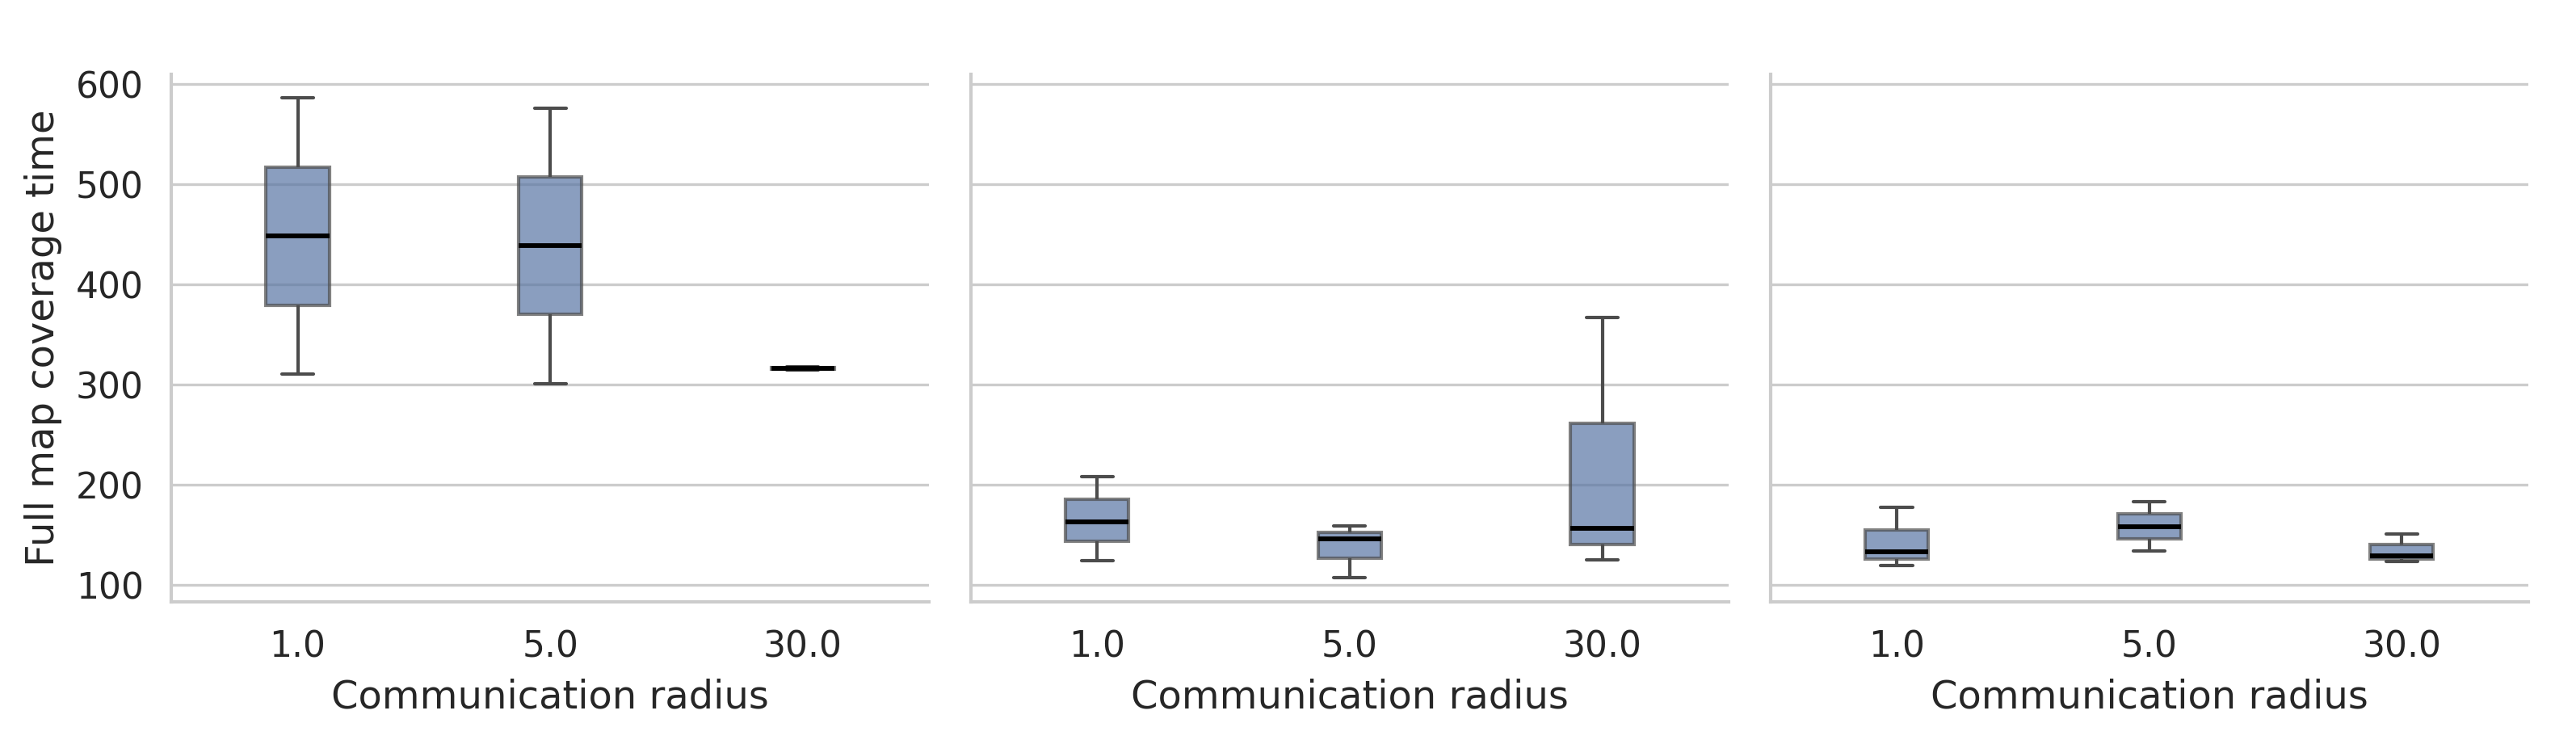

In [26]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(
    style="whitegrid",
    context="paper",
    font_scale=1.2,   
)

g = sns.catplot(
    data=cover_df,
    x="comm_radius",
    y="cover_time",
    col="n_agents",
    kind="box",
    showfliers=False,
    height=3.2,        
    aspect=1.1,
    width=0.25,
    color="#4C72B0",  
    linewidth=1.0,
    boxprops=dict(alpha=0.7),
    whiskerprops=dict(linewidth=1.0),
    capprops=dict(linewidth=1.0),
    medianprops=dict(color="black", linewidth=1.4),
)

g.set_axis_labels(
    "Communication radius",
    "Full map coverage time"
)

# g.set_titles("UAVs = {col_name}")
g.set_titles(" ")

# Clean spines
for ax in g.axes.flat:
    sns.despine(ax=ax)

plt.tight_layout()
plt.savefig("full_map_coverage_vs_comm_radius.pdf", bbox_inches="tight")
plt.show()




### KL Divergence

In [27]:
BATCH_DIR = Path("/home/gaby/Documents/UCB/AAM/GIT/sastryrepo/MarkovErgodic/MAES/results/Analysis_Comms_Init6_021126")
for run_dir in list(BATCH_DIR.iterdir()):
    npz = load_run_npz(run_dir)
    print(run_dir.name, "→", get_method_label(npz))
print(len(list(BATCH_DIR.iterdir())))

T1000_ergodic_GPupdate50_remc_Pupdate50_v1_gpucb_static_3_start09x3_commModelocal_comm_radius1.0_concenIter5 → ergodic-remc-ucb
T1000_ergodic_GPupdate50_remc_Pupdate50_v3_gpucb_static_6_start54x6_commModelocal_comm_radius30.0_concenIter5 → ergodic-remc-ucb
T1000_ergodic_GPupdate50_remc_Pupdate50_v3_gpucb_static_10_start91x10_commModelocal_comm_radius30.0_concenIter5 → ergodic-remc-ucb
T1000_ergodic_GPupdate50_remc_Pupdate50_v3_gpucb_static_6_start07x6_commModelocal_comm_radius5.0_concenIter5 → ergodic-remc-ucb
T1000_ergodic_GPupdate50_remc_Pupdate50_v3_gpucb_static_6_start90x6_commModelocal_comm_radius30.0_concenIter5 → ergodic-remc-ucb
T1000_ergodic_GPupdate50_remc_Pupdate50_v3_gpucb_static_10_start91x10_commModelocal_comm_radius5.0_concenIter5 → ergodic-remc-ucb
T1000_ergodic_GPupdate50_remc_Pupdate50_v3_gpucb_static_10_start91x10_commModelocal_comm_radius1.0_concenIter5 → ergodic-remc-ucb
T1000_ergodic_GPupdate50_remc_Pupdate50_v1_gpucb_static_3_start49x3_commModelocal_comm_radius1.

In [28]:
def kl_divergence(p, q, eps=1e-12):
    p = np.clip(p, eps, None)
    q = np.clip(q, eps, None)
    return np.sum(p * np.log(p / q))

In [29]:
rows = []

for run_dir in BATCH_DIR.iterdir():
    if not run_dir.is_dir():
        continue

    npz = load_run_npz(run_dir)

    n_agents = int(npz["n_agents"])
    comm_radius = float(npz["comm_radius"])

    phi_agents_time = npz["phi_agents_time"]   # (T, n_agents, nstates)
    gp_update_steps = npz["gp_update_steps"]   # (n_updates,)

    for t in gp_update_steps:
        phis = phi_agents_time[t]  # (n_agents, nstates)

        # normalize defensively
        phis = phis / phis.sum(axis=1, keepdims=True)

        phi_mean = phis.mean(axis=0)

        kl_vals = [
            kl_divergence(phis[a], phi_mean)
            for a in range(n_agents)
        ]

        rows.append({
            "time": int(t),
            "kl_mean": float(np.mean(kl_vals)),
            "kl_std": float(np.std(kl_vals)),
            "n_agents": n_agents,
            "comm_radius": comm_radius,
            "run": run_dir.name,
        })

kl_df = pd.DataFrame(rows)


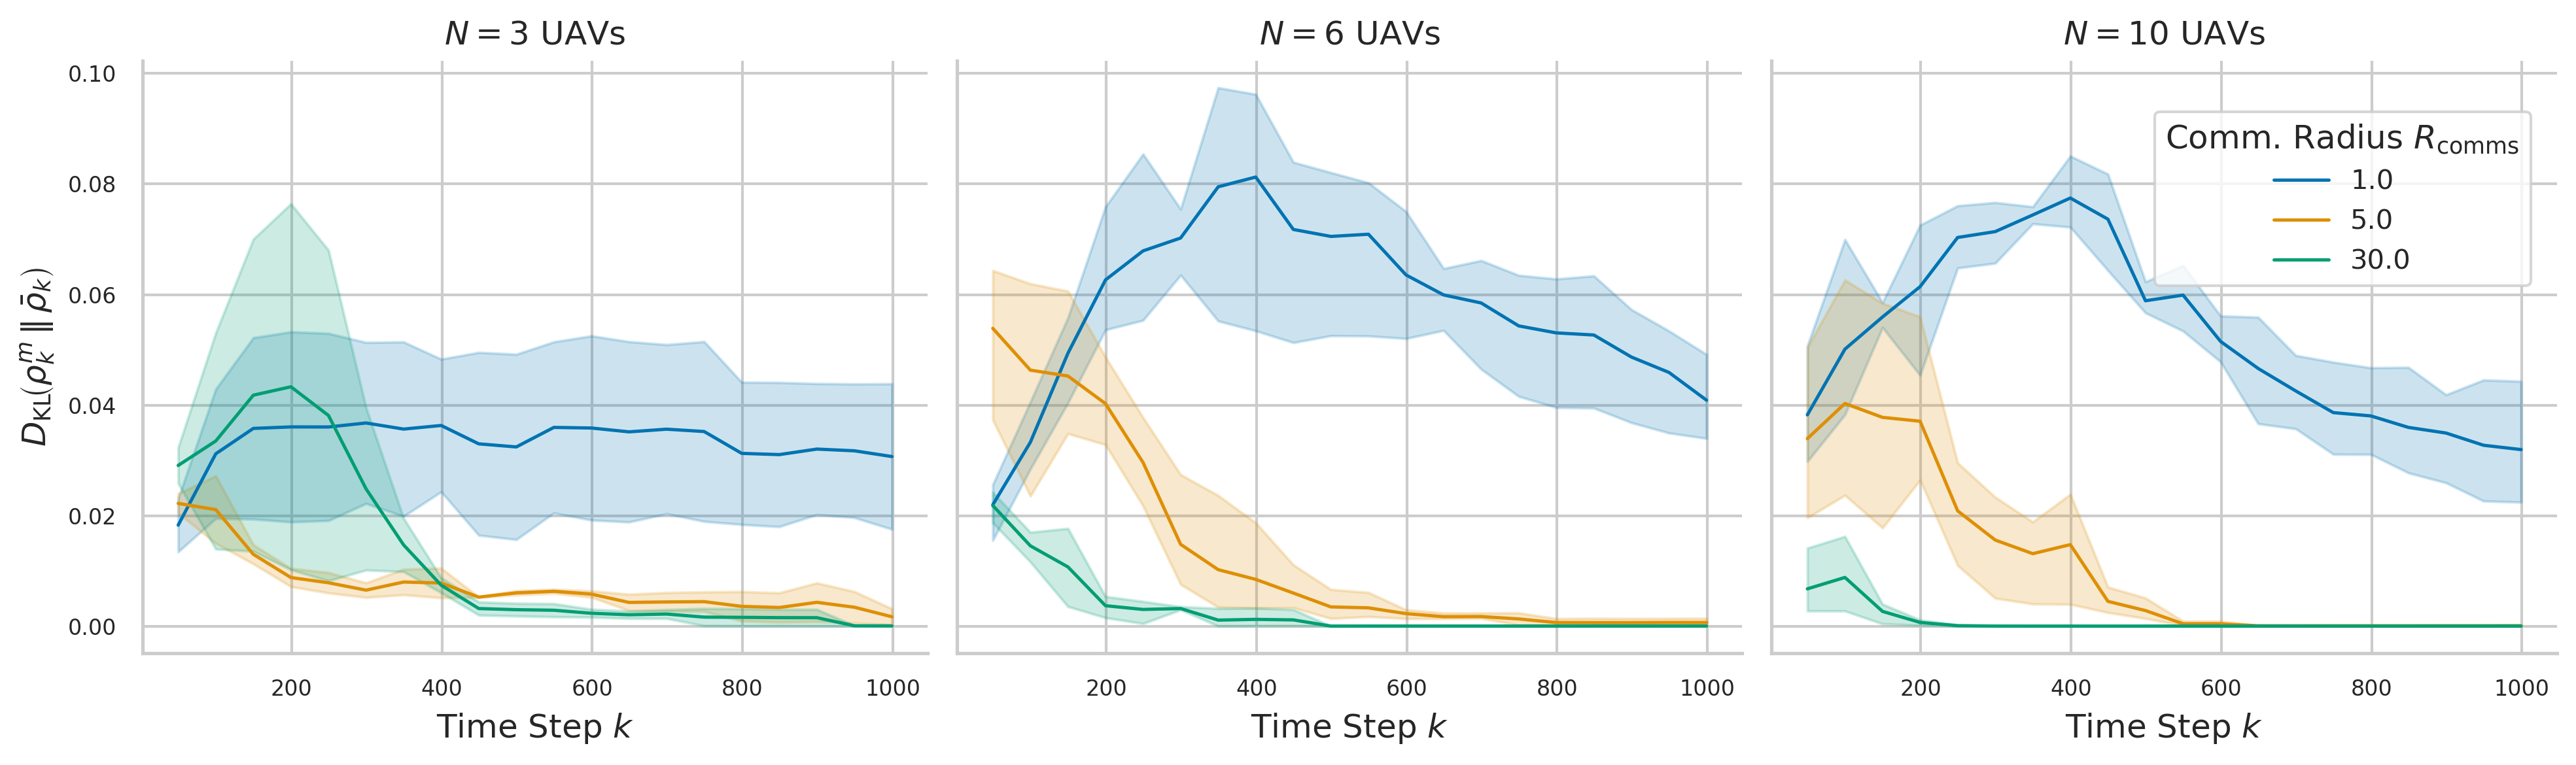

In [45]:
import matplotlib as mpl
import seaborn as sns
import matplotlib.pyplot as plt

g = sns.relplot(
    data=kl_df,
    x="time",
    y="kl_mean",
    hue="comm_radius",
    col="n_agents",
    kind="line",
    palette="colorblind",
    height=4,
    aspect=1.0,
    facet_kws=dict(sharey=True, sharex=True),
)

# IEEE-style axis labels
g.set_axis_labels(
    "Time Step $k$",
    r"$D_{\mathrm{KL}}\!\left(\rho_k^{m} \,\|\, \bar{\rho}_k\right)$"

)

g.set_titles(r"$N = {col_name}$ UAVs")

# --- Legend formatting ---
g._legend.set_title(r"Comm. Radius $R_{\mathrm{comms}}$")
g._legend.set_bbox_to_anchor((0.98, 0.85))   # top-right inside figure
g._legend._loc = 1  # 1 = 'upper right'
g._legend.set_frame_on(True)
# g._legend.set_ncol(len(kl_df["comm_radius"].unique()))

# Remove top/right spines
for ax in g.axes.flat:
    sns.despine(ax=ax)

plt.tight_layout()


In [ ]:
rows = []

for run_dir in BATCH_DIR.iterdir():
    if not run_dir.is_dir():
        continue

    npz = load_run_npz(run_dir)

    n_agents = int(npz["n_agents"])
    comm_radius = float(npz["comm_radius"])

    T = int(npz["T"])

    for t in range(T):


        rows.append({
            "time": t,
            # "coverage": frac,
            "n_agents": n_agents,
            "comm_radius": comm_radius,
            "run": run_dir.name,
        })

cov_df = pd.DataFrame(rows)


In [ ]:
cov_df = pd.DataFrame(rows)
g = sns.relplot(
    data=cov_df,
    x="time",
    y="coverage",
    hue="comm_radius",
    col="n_agents",
    kind="line",
    palette="colorblind",
    height=4,
    aspect=1.0,
)


g.set_axis_labels("Timestep", "Fraction of map explored")
# g.set_titles("UAVs = {col_name}")
g.set_titles(" ")

for ax in g.axes.flat:
    ax.set_ylim(0.9, 1.01)   
    sns.despine(ax=ax)

plt.tight_layout()
plt.savefig("fracKL_.png", bbox_inches="tight")
plt.show()


In [ ]:
cov_df_500 = cov_df[cov_df["time"] <= 500]
g = sns.relplot(
    data=cov_df_500,
    x="time",
    y="coverage",
    hue="comm_radius",
    col="n_agents",
    kind="line",
    palette="colorblind",
    height=4,
    aspect=1.0,
)

g.set_axis_labels("Time", "Fraction of map explored")
# g.set_titles("Number of UAVs = {col_name}")
g.set_titles(" ")

for ax in g.axes.flat:
    sns.despine(ax=ax)

plt.tight_layout()


### Analysis P Matrix

In [ ]:
BATCH_DIR = Path("/home/gaby/Documents/UCB/AAM/GIT/sastryrepo/MarkovErgodic/MAES/results/P_GPupdate_dyn2_T2000")
for run_dir in list(BATCH_DIR.iterdir()):
    print(run_dir.name)
    npz = load_run_npz(run_dir)

print(len(list(BATCH_DIR.iterdir())))

In [ ]:
roi_rows = []

for run_dir in BATCH_DIR.iterdir():
    if not run_dir.is_dir():
        continue

    npz = load_run_npz(run_dir)

    traj_rc = np.asarray(npz["traj_rc_agents_all"])   # (T, n_agents, 2)
    true_phi_map_time = npz["true_phi_map_time"]
    n_agents = int(npz["n_agents"])
    map_id = extract_map_id_from_name(run_dir.name)
    agent_starts = extract_start_from_name(run_dir.name)

    # cfg starts (absolute times)
    cfg_starts = detect_cfg_starts(true_phi_map_time)
    cfg_cols = [f"cfg{i}_t={cfg_starts[i]}" for i in range(len(cfg_starts))]

    # ROI geometry sets (r,c)
    roi_sets = build_roi_cellsets(
        npz.get("roi_rc", []),
        npz.get("roi_name", [])
    )

    for roi_name, cellset in roi_sets.items():
        # canonical metric call: returns one value per cfg (offset relative to cfg start)
        t_rel_vec = roi_first_visit_per_cfg(
            traj_rc=traj_rc,
            roi_cellset=cellset,
            cfg_starts=cfg_starts,
        )
        # print(f"Run {run_dir.name}, ROI {roi_name}, t_rel_vec: {t_rel_vec}")
        if t_rel_vec is None or np.isnan(t_rel_vec).any():
            print(f"Run {run_dir.name}, ROI {roi_name} with Nan")

        row = {
            "map_id": map_id,
            "agent_starts": agent_starts,
            # "run": run_dir.name,
            "n_agents": n_agents,
            "gp_update": int(npz["gp_update"]),
            "p_update": int(npz["p_update"]),
            "roi": roi_name,
        }

        # write into columns
        for i, col in enumerate(cfg_cols):
            row[col] = t_rel_vec[i]  # may be np.nan

        roi_rows.append(row)

roi_df = (
    pd.DataFrame(roi_rows)
    .sort_values(["n_agents", "gp_update", "p_update", "roi", "map_id", "agent_starts"])
    .reset_index(drop=True)
)

with pd.option_context("display.max_rows", None):
    display(roi_df)



In [ ]:

cover_rows = []

for run_dir in BATCH_DIR.iterdir():
    if not run_dir.is_dir():
        continue

    npz = load_run_npz(run_dir)

    traj_states = npz["traj_states"]       
    n_agents = int(npz["n_agents"])
    nstates = int(npz["nstates"])

    map_id = extract_map_id_from_name(run_dir.name)
    agent_starts = extract_start_from_name(run_dir.name)

    cover_time = full_map_cover_time(
        traj_states=traj_states,
        nstates=nstates,
    )

    cover_rows.append({
        "map_id": map_id,
        "agent_starts": agent_starts,
        "n_agents": n_agents,
        "gp_update": int(npz["gp_update"]),
        "p_update": int(npz["p_update"]),
        "full_map_cover_time": cover_time,
    })

cover_df = (
    pd.DataFrame(cover_rows)
    .sort_values(["n_agents", "gp_update", "p_update", "map_id", "agent_starts"])
    .reset_index(drop=True)
)

with pd.option_context("display.max_rows", None):
    display(cover_df)

In [ ]:
curves = defaultdict(lambda: {
    "emp_bel": [],
    "bel_true": [],
})

for run_dir in BATCH_DIR.iterdir():
    if not run_dir.is_dir():
        continue

    data = load_run_npz(run_dir)


    state_index_map = recover_state_index_map(data)
    nstates = len(state_index_map)

    class DummyEnv:
        def __init__(self, nstates):
            self.nstates = nstates

    env = DummyEnv(nstates)

    err_emp_bel, err_bel_true = convergence_errors_from_run(
        traj_states=data["traj_states"],
        belief_phi_map=data["belief_phi_map"],
        true_phi_map_time=data["true_phi_map_time"],
        env=env,
        empirical_fn=empirical_from_traj,
    )

    key = (
        int(data["n_agents"]),
        int(data["gp_update"]),
        int(data["p_update"]),
    )

    curves[key]["emp_bel"].append(err_emp_bel)
    curves[key]["bel_true"].append(err_bel_true)



In [ ]:
plt.rcParams.update({
    "font.size": 16,
    "axes.labelsize": 18,
    "axes.titlesize": 20,
    "legend.fontsize": 14,
    "lines.linewidth": 2.2,
})


update_pairs = sorted({
    (gp_u, p_u)
    for (n_agents, gp_u, p_u) in curves.keys()
})

base_colors = [
    "#1f77b4",  # blue
    "#ff7f0e",  # orange
    "#2ca02c",  # dark green
    "#9467bd",  # purple
    "#d62728",  # muted red
    "#8c564b",  # brown
    "#e377c2",  # pink
]

if len(update_pairs) > len(base_colors):
    raise ValueError(
        f"Need {len(update_pairs)} colors but only {len(base_colors)} provided. "
        "Add more colors explicitly."
    )

color_map = {
    pair: base_colors[i]
    for i, pair in enumerate(update_pairs)
}

all_n_agents = sorted({k[0] for k in curves.keys()})
target_n_agents = all_n_agents[0]   # change if needed

items = [
    (k, v) for k, v in curves.items()
    if k[0] == target_n_agents
]

fig, ax = plt.subplots(figsize=(10, 5))

for (n_agents, gp_u, p_u), data in items:
    color = color_map[(gp_u, p_u)]

    # ---------- empirical vs belief ----------
    Y = data["emp_bel"]
    min_len = min(len(y) for y in Y)
    Y = np.stack([y[:min_len] for y in Y])

    mean = Y.mean(axis=0)
    std  = Y.std(axis=0)
    x = np.arange(min_len)

    ax.plot(x, mean, color=color, ls="-")
    ax.fill_between(
        x,
        mean - std,
        mean + std,
        color=color,
        alpha=0.10,
        linewidth=0,
    )

    # ---------- belief vs true ----------
    Y2 = data["bel_true"]
    min_len2 = min(len(y) for y in Y2)
    min_len_common = min(min_len, min_len2)

    Y2 = np.stack([y[:min_len_common] for y in Y2])
    mean2 = Y2.mean(axis=0)
    std2  = Y2.std(axis=0)

    ax.plot(
        x[:min_len_common],
        mean2,
        color=color,
        ls="--",
    )
    ax.fill_between(
        x[:min_len_common],
        mean2 - std2,
        mean2 + std2,
        color=color,
        alpha=0.10,
        linewidth=0,
    )


ax.set_xlabel("Time step")
ax.set_ylabel(r"$\ell_1$ error")
ax.yaxis.set_major_locator(plt.MultipleLocator(0.25))
# ax.set_title(f"Convergence ({target_n_agents} agent{'s' if target_n_agents > 1 else ''})")

ax.grid(True, axis="y", alpha=0.3)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)


update_handles = [
    Line2D(
        [0], [0],
        color=color_map[pair],
        lw=2.2,
        label=f"GP={pair[0]}, P={pair[1]}"
    )
    for pair in update_pairs
]

metric_handles = [
    Line2D(
        [0], [0],
        color="black",
        lw=2.2,
        ls="-",
        label=r"$\|\hat{\rho}_k - \bar{\rho}_k\|_1$"
    ),
    Line2D(
        [0], [0],
        color="black",
        lw=2.2,
        ls="--",
        label=r"$\|\bar{\rho}_k - \rho_k^\star\|_1$"
    ),
]

leg1 = ax.legend(
    handles=update_handles,
    title="Update frequency",
    loc="upper right",
    frameon=False,
)

leg2 = ax.legend(
    handles=metric_handles,
    title="Metric",
    loc="upper center",
    frameon=False,
)

ax.add_artist(leg1)

plt.tight_layout()
plt.show()